# Camera calibration capture in Webots

Moves the chessboard object through many poses via the scene REST API, grabs a camera frame at each pose, keeps only frames where the full board is detected, then runs `cv2.calibrateCamera`.

In [1]:
import math, time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import requests
from IPython.display import clear_output

# ---------------- CONFIG ----------------
API_URL    = "http://localhost:8002"          # scene_manipulator REST API
OBJECT     = "CHESSBOARD"                     # DEF name of the chessboard node
SNAPSHOT_URL = "http://localhost:9090/snapshot?topic=/object_detector/camera/image_color"

PATTERN    = (8, 6)       # INNER corners (cols, rows) = squares - 1
SQUARE     = 0.025        # square size in metres
N_IMAGES   = 40           # number of *valid* images to collect
MAX_TRIES  = 256          # give up after this many poses
OUT_DIR    = Path("calibration_images")
SETTLE     = 0.6          # seconds to wait after moving the board

# Chessboard position limits:
X_LIM = (-0.25, -0.05)     
Y_LIM = (-0.20,  0.20)     
Z_LIM = ( 0.15,  0.25)
MAX_TILT = math.radians(10) # board tilt around each of its own axes
SEED     = 42

In [2]:
def get_pose(name):
    r = requests.get(f"{API_URL}/objects/{name}/pose", timeout=5)
    r.raise_for_status()
    return r.json()

def set_pose(name, **pose):
    """pose: position=[x,y,z] and/or rpy / quaternion / axis_angle."""
    r = requests.put(f"{API_URL}/objects/{name}/pose", json=pose, timeout=5)
    r.raise_for_status()

objects = requests.get(f"{API_URL}/objects", timeout=5).json()["objects"]
print("Objects:", [o["name"] for o in objects])
start = get_pose(OBJECT)
print("Start pose:", start)

Objects: ['ROBOT', 'TARGET_BOX', 'CHESSBOARD', 'ARUCO_5', 'BLUE_HEXAGON']
Start pose: {'name': 'CHESSBOARD', 'type': 'Chessboard', 'position': [-0.15, 0.25, 0.0], 'axis_angle': [0.0, 0.0, 1.0, 0.0], 'quaternion': [0.0, 0.0, 0.0, 1.0]}


In [3]:
def axis_angle_to_matrix(aa):
    x, y, z, a = aa
    n = np.array([x, y, z], float)
    n = n / (np.linalg.norm(n) or 1.0)
    return cv2.Rodrigues(n * a)[0]

def matrix_to_axis_angle(R):
    rvec = cv2.Rodrigues(R)[0].ravel()
    a = float(np.linalg.norm(rvec))
    axis = rvec / a if a > 1e-9 else np.array([0.0, 0.0, 1.0])
    return [float(axis[0]), float(axis[1]), float(axis[2]), a]

start_pos = np.array(start["position"], float)
start_R   = axis_angle_to_matrix(start["axis_angle"]) # Webots [x, y, z, angle]
rng = np.random.default_rng(SEED)

def random_pose():
    """Random position around the start pose + random tilt in the board's own frame."""
    pos = [rng.uniform(*X_LIM),
           rng.uniform(*Y_LIM),
           rng.uniform(*Z_LIM)]

    tilt = rng.uniform(-MAX_TILT, MAX_TILT, size=3)
    R = start_R @ cv2.Rodrigues(tilt)[0]
    return pos, matrix_to_axis_angle(R)

In [4]:
def get_snapshot(retries=3):
    """Fetch ONE JPEG from web_video_server and decode it to a BGR image."""
    for attempt in range(retries):
        try:
            r = requests.get(SNAPSHOT_URL, timeout=5)
            r.raise_for_status()
            frame = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
            if frame is not None:
                return frame
        except requests.RequestException as exc:
            print(f"snapshot attempt {attempt + 1} failed: {exc}")
        time.sleep(0.2)
    return None


def find_corners(gray):
    flags = cv2.CALIB_CB_NORMALIZE_IMAGE | cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY
    found, corners = cv2.findChessboardCornersSB(gray, PATTERN, flags)
    if found:
        return True, corners
    found, corners = cv2.findChessboardCorners(
        gray, PATTERN, cv2.CALIB_CB_ADAPTIVE_THRESH | cv2.CALIB_CB_NORMALIZE_IMAGE)
    if found:
        corners = cv2.cornerSubPix(
            gray, corners, (11, 11), (-1, -1),
            (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3))
    return found, corners

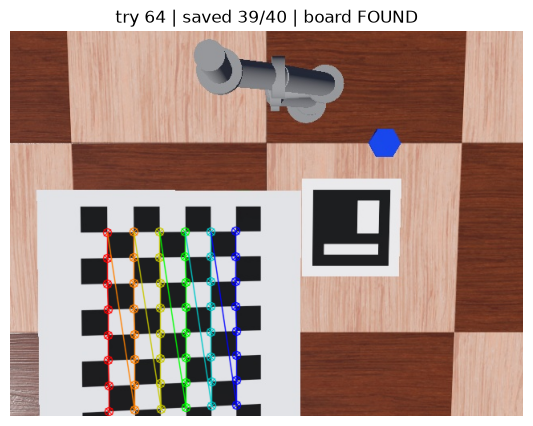

Done: 40 valid images in calibration_images/ (64 poses tried). Board pose restored.


In [5]:
OUT_DIR.mkdir(exist_ok=True)
for f in OUT_DIR.glob("img_*.png"): # start clean
    f.unlink()

saved, tries = 0, 0

try:
    while saved < N_IMAGES and tries < MAX_TRIES:
        tries += 1
        pos, aa = random_pose()
        set_pose(OBJECT, position=pos, axis_angle=aa)
        time.sleep(SETTLE)

        get_snapshot() # clear old image
        frame = get_snapshot()
        if frame is None:
            print(f"[{tries}] no frame"); continue

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        found, corners = find_corners(gray)

        preview = frame.copy()
        cv2.drawChessboardCorners(preview, PATTERN, corners, found)
        clear_output(wait=True)
        plt.figure(figsize=(7, 5))
        plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)); plt.axis("off")
        plt.title(f"try {tries} | saved {saved}/{N_IMAGES} | board {'FOUND' if found else 'not found'}")
        plt.show()

        if found:
            cv2.imwrite(str(OUT_DIR / f"img_{saved:03d}.png"), frame) # save the camera frame
            saved += 1
finally:
    restore = {k: start[k] for k in ("position", "axis_angle") if k in start}
    set_pose(OBJECT, **restore)
    print(f"Done: {saved} valid images in {OUT_DIR}/ ({tries} poses tried). Board pose restored.")

Using 40 images, size (640, 480)

RMS reprojection error: 0.0284 px
Camera matrix K:
 [[771.5562837    0.         319.12289015]
 [  0.         771.56237655 239.35190286]
 [  0.           0.           1.        ]]
Distortion (k1 k2 p1 p2 k3): [-9.54646985e-04  9.40566150e-03  5.48571102e-05 -4.07191563e-05
 -3.67333565e-02]


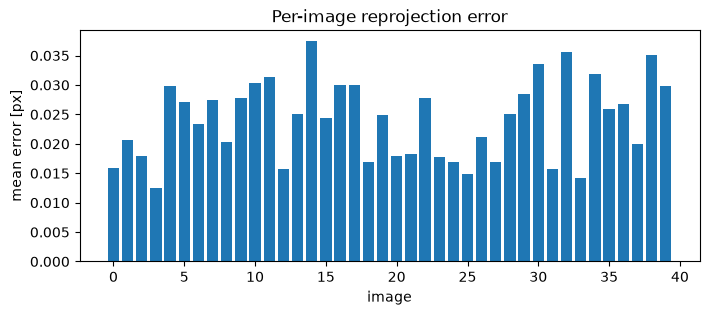

Saved camera_calibration.npz


In [6]:
# ---------- Calibration ----------
objp = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE

obj_points, img_points, used = [], [], []
img_size = None
for path in sorted(OUT_DIR.glob("img_*.png")):
    img = cv2.imread(str(path))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_size = gray.shape[::-1]
    found, corners = find_corners(gray)
    if found:
        obj_points.append(objp); img_points.append(corners); used.append(path.name)

print(f"Using {len(used)} images, size {img_size}")

rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(obj_points, img_points, img_size, None, None)
print(f"\nRMS reprojection error: {rms:.4f} px")
print("Camera matrix K:\n", K)
print("Distortion (k1 k2 p1 p2 k3):", dist.ravel())

# Per-image error -> spot bad frames
errs = []
for i in range(len(obj_points)):
    proj, _ = cv2.projectPoints(obj_points[i], rvecs[i], tvecs[i], K, dist)
    diff = img_points[i].reshape(-1, 2) - proj.reshape(-1, 2)   # OpenCV 5 returns different shapes
    errs.append(float(np.mean(np.linalg.norm(diff, axis=1))))
plt.figure(figsize=(8, 3)); plt.bar(range(len(errs)), errs)
plt.xlabel("image"); plt.ylabel("mean error [px]"); plt.title("Per-image reprojection error"); plt.show()

np.savez("camera_calibration.npz", K=K, dist=dist, rms=rms, img_size=img_size)
print("Saved camera_calibration.npz")